[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anderson-perez/IAC/blob/main/4%20-%20Aprendizado%20Profundo/Tutorial_Keras.ipynb)

# Inteligência Artificial e Computacional

## Segunda Parte da Disciplina

# Informações:

- Prof. Anderson Luiz Fernandes Perez
- Contato: anderson.perez@ufsc.br | anderson.lfp@gmail.com
- Os materiais da disciplina estarão disponíveis no github (https://github.com/anderson-perez/IAC.git)

# Fundamentos de Keras

O Keras é uma API de alto nível para desenvolver, treinar e avaliar redes neurais artificiais.

A partir do Keras 3, é possível utilizar diferentes backends de computação, incluindo:
- TensorFlow: muito utilizado no desenvolvimento e na implantação de modelos.
- PyTorch: popular em pesquisa e desenvolvimento de modelos de aprendizado profundo.
- JAX: voltado a computação numérica de alto desempenho e diferenciação automática.

In [1]:
# Execute apenas se precisar instalar dependências:
# %pip install -U keras tensorflow scikit-learn matplotlib pandas

In [2]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"  # antes de importar keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, mean_absolute_error,
                             mean_squared_error, r2_score)

keras.utils.set_random_seed(42)
print("Keras:", keras.__version__)
print("Backend:", keras.backend.backend())

Keras: 3.12.4
Backend: tensorflow


## Modelos em Keras

O fluxo típico para criar um modelo em Keras é:

1. Preparar dados; 
2. Definir arquitetura; 
3. Compilar (otimizador, perda, métricas); 
4. Treinar; 
5. Avaliar e predizer.

**Conceitos:** uma *camada* transforma tensores; os *pesos* são parâmetros aprendidos; a *função de perda* quantifica o erro; o *otimizador* atualiza os parâmetros; as *métricas* ajudam a interpretar o desempenho.

## As Três Formas de se Construir Modelos em Keras

In [3]:
X_and = np.array([[0,0],[0,1],[1,0],[1,1]], dtype="float32")
y_and = np.array([[0],[0],[0],[1]], dtype="float32")

print(pd.DataFrame(np.column_stack([X_and, y_and]), columns=["x1", "x2", "AND"]))

    x1   x2  AND
0  0.0  0.0  0.0
1  0.0  1.0  0.0
2  1.0  0.0  0.0
3  1.0  1.0  1.0


### Exemplo com Sequential

Adequada para uma **sequência linear de camadas**. É a API mais simples quando cada camada recebe uma única saída da anterior.

In [5]:
modelo_seq = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(1, activation="sigmoid")
], name="and_sequencial")

modelo_seq.summary()

Model: "and_sequencial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

### Exemplo com Functional API

Permite grafos com **múltiplas entradas, múltiplas saídas e ramificações**. Define explicitamente a ligação entre tensores.

In [6]:
entrada = keras.Input(shape=(2,), name="entrada")
saida = layers.Dense(1, activation="sigmoid", name="saida")(entrada)
modelo_func = keras.Model(inputs=entrada, outputs=saida, name="and_funcional")

modelo_func.summary()

Model: "and_funcional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)            │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

### Exemplo com Model Subclassing

Herança de `keras.Model`. As camadas são criadas em `__init__()` e a propagação é calculada no método `call()`. É útil quando a lógica do modelo exige controle programático.

In [ ]:
class ModeloAND(keras.Model):
    def __init__(self):
        super().__init__()
        self.saida = layers.Dense(1, activation="sigmoid")

    def call(self, inputs):
        return self.saida(inputs)

modelo_sub = ModeloAND()

_ = modelo_sub(X_and[:1])  # constrói os pesos

modelo_sub.summary()

tf.Tensor([[0. 0.]], shape=(1, 2), dtype=float32)
tf.Tensor([[0. 0.]], shape=(1, 2), dtype=float32)


Model: "modelo_and_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (1, 1)                 │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

### Treinamento

Todas as APIs podem utilizar `compile()`, `fit()`, `evaluate()` e `predict()`.

In [8]:
modelos_and = {"Sequential": modelo_seq, "Functional": modelo_func, "Subclassing": modelo_sub}
for nome, modelo in modelos_and.items():
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.1),
                   loss="binary_crossentropy", metrics=["accuracy"])
    modelo.fit(X_and, y_and, epochs=250, verbose=0)
    probs = modelo.predict(X_and, verbose=0).ravel()
    print(nome, "probabilidades:", np.round(probs, 3),
          "classes:", (probs >= 0.5).astype(int))

Sequential probabilidades: [0.    0.048 0.048 0.943] classes: [0 0 0 1]
Functional probabilidades: [0.    0.046 0.046 0.945] classes: [0 0 0 1]
Subclassing probabilidades: [0.    0.042 0.042 0.951] classes: [0 0 0 1]


**Discussão:** o modelo original da porta AND equivale a uma regressão logística (um neurônio sigmoide). Para XOR, que não é linearmente separável, acrescente ao menos uma camada oculta não linear. Model Subclassing permite também sobrescrever `train_step()` para personalizar o treinamento.

## Funções de Ativação
Uma camada densa calcula $z=Wx+b$ e aplica $a=f(z)$. Sem não linearidade nas camadas ocultas, várias camadas densas equivalem a uma única transformação afim.

| Ativação | Expressão / comportamento | Uso comum |
|---|---|---|
| Linear | $f(x)=x$ | Saída de regressão |
| Sigmoid | $1/(1+e^{-x})$ | Saída binária |
| Tanh | Valores entre −1 e 1 | Camadas ocultas, alguns modelos recorrentes |
| ReLU | $\max(0,x)$ | Camadas ocultas |
| Leaky ReLU | Inclinação pequena para $x<0$ | Alternativa à ReLU |
| ELU | Exponencial para entradas negativas | Camadas ocultas |
| GELU | Ativação suave | Redes modernas, Transformers |
| Softmax | Normaliza um vetor em probabilidades que somam 1 | Saída multiclasse exclusiva |

**Atenção:** Softmax opera sobre um **vetor de logits**; não é uma função escalar independente por neurônio.

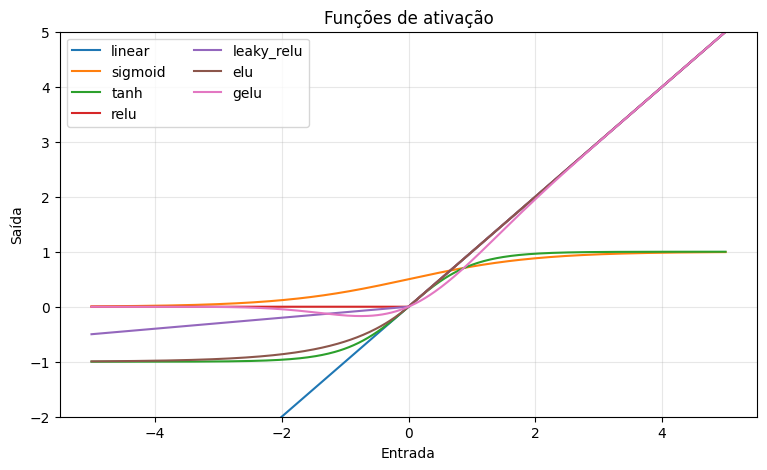

Softmax [1, 2, 3]: [[0.09003057 0.24472847 0.66524096]]


In [9]:
x = np.linspace(-5, 5, 400, dtype="float32")
funcoes = {
    "linear": lambda x: x,
    "sigmoid": keras.activations.sigmoid,
    "tanh": keras.activations.tanh,
    "relu": keras.activations.relu,
    "leaky_relu": lambda x: keras.activations.leaky_relu(x, negative_slope=0.1),
    "elu": keras.activations.elu,
    "gelu": keras.activations.gelu,
}
fig, ax = plt.subplots(figsize=(9,5))
for nome, f in funcoes.items():
    ax.plot(x, np.asarray(f(x)), label=nome)
ax.set(xlabel="Entrada", ylabel="Saída", title="Funções de ativação")
ax.set_ylim(-2, 5); ax.grid(alpha=.3); ax.legend(ncol=2)
plt.show()
print("Softmax [1, 2, 3]:", np.asarray(keras.activations.softmax(np.array([[1.,2.,3.]]))))

## Otimizadores e Taxa de Aprendizado

O treinamento procura minimizar a função de perda $L(\theta)$. No gradiente descendente, $\theta_{t+1}=\theta_t-\eta\nabla_\theta L$, em que $\eta$ é a **taxa de aprendizado**.

| Otimizador Keras | Ideia principal |
|---|---|
| `SGD` | Gradiente descendente; admite `momentum` e Nesterov |
| `RMSprop` | Ajuste adaptativo por média móvel dos gradientes quadráticos |
| `Adam` | Momentos de primeira e segunda ordem |
| `AdamW` | Adam com decaimento de pesos desacoplado |
| `Adagrad` | Acumula gradientes quadráticos; útil para dados esparsos |
| `Adadelta` | Variante adaptativa do Adagrad |
| `Adamax` | Variante de Adam baseada na norma infinita |
| `Nadam` | Adam com momentum de Nesterov |
| `Ftrl` | Otimização regularizada, comum em modelos esparsos |
| `Lion` | Atualizações baseadas no sinal de momentum (quando disponível na versão) |
| `Lamb` | Otimizador adaptativo para treinamento em larga escala (quando disponível na versão) |
| `Muon` | Otimizador para determinados parâmetros matriciais (quando disponível na versão) |

A disponibilidade exata varia com a **versão do Keras e o backend**. Consulte `keras.optimizers` e https://keras.io/api/optimizers/. `Momentum` não é um otimizador separado: é uma opção de `SGD`.

In [10]:
# Verifique os otimizadores disponíveis na instalação:
nomes = ["SGD", "RMSprop", "Adam", "AdamW", "Adagrad", "Adadelta",
         "Adamax", "Nadam", "Ftrl", "Lion", "Lamb", "Muon"]
print({nome: hasattr(keras.optimizers, nome) for nome in nomes})

sgd_momentum = keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
adam = keras.optimizers.Adam(learning_rate=0.001)
print(sgd_momentum, adam)

{'SGD': True, 'RMSprop': True, 'Adam': True, 'AdamW': True, 'Adagrad': True, 'Adadelta': True, 'Adamax': True, 'Nadam': True, 'Ftrl': True, 'Lion': True, 'Lamb': True, 'Muon': True}
<keras.src.optimizers.sgd.SGD object at 0x000002A7A8327BB0> <keras.src.optimizers.adam.Adam object at 0x000002A7ECE3A080>


### Influência da Taxa de Aprendizado

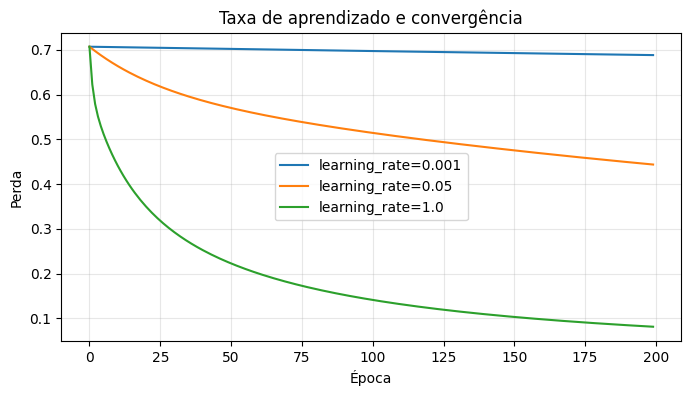

In [11]:
historicos_lr = {}
for taxa in [0.001, 0.05, 1.0]:
    keras.utils.set_random_seed(123)
    m = keras.Sequential([layers.Input(shape=(2,)), layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=keras.optimizers.SGD(learning_rate=taxa),
              loss="binary_crossentropy")
    historicos_lr[taxa] = m.fit(X_and, y_and, epochs=200, verbose=0).history["loss"]
plt.figure(figsize=(8,4))
for taxa, perdas in historicos_lr.items():
    plt.plot(perdas, label=f"learning_rate={taxa}")
plt.xlabel("Época"); plt.ylabel("Perda"); plt.title("Taxa de aprendizado e convergência")
plt.legend(); plt.grid(alpha=.3); plt.show()

### Ajustando a Taxa de Aprendizado

Além de escolher uma taxa fixa, podemos usar *schedules* e callbacks. `ReduceLROnPlateau` reduz a taxa quando a métrica monitorada deixa de melhorar; `EarlyStopping` interrompe o treinamento após um período sem melhora.

In [12]:
callbacks_exemplo = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=5, min_lr=1e-6)
]
# Usaremos callbacks nos exemplos com datasets reais.

## Funções de Perda
A função de perda é otimizada durante o treinamento. **Métricas** podem ser diferentes da perda. A escolha depende do problema e da representação do alvo.

| Problema | Perdas Keras comuns | Observação |
|---|---|---|
| Regressão | `MeanSquaredError`, `MeanAbsoluteError`, `Huber`, `LogCosh`, `MeanAbsolutePercentageError`, `MeanSquaredLogarithmicError` | MSE penaliza mais erros grandes; MAE é menos sensível a outliers |
| Classificação binária | `BinaryCrossentropy`, `BinaryFocalCrossentropy` | Sigmoid ou logits; focal dá mais peso a exemplos difíceis |
| Multiclasse com rótulos inteiros | `SparseCategoricalCrossentropy` | Classes 0, 1, 2... |
| Multiclasse com one-hot | `CategoricalCrossentropy`, `CategoricalFocalCrossentropy` | Vetores de probabilidades/one-hot |
| Distribuições | `KLDivergence` | Compara distribuições |
| Similaridade / ranking | `CosineSimilarity`, `Hinge`, `SquaredHinge`, `CategoricalHinge` | Dependem da codificação e do objetivo |
| Contagens | `Poisson` | Modelagem de contagens |

Consulte a lista atualizada: https://keras.io/api/losses/. Algumas perdas são especializadas e sua disponibilidade depende da versão.

### MSE, MAE e Entropia Cruzada

Para $n$ exemplos, $\mathrm{MSE}=\frac1n\sum_i(y_i-\hat y_i)^2$ e $\mathrm{MAE}=\frac1n\sum_i|y_i-\hat y_i|$.

Para classificação binária, $\mathrm{BCE}=-\frac1n\sum_i[y_i\log(\hat y_i)+(1-y_i)\log(1-\hat y_i)]$.

Com saída `sigmoid`, use `BinaryCrossentropy(from_logits=False)`; se a camada produzir valores brutos (*logits*), use `from_logits=True`. Evite aplicar sigmoid duas vezes.

In [13]:
y_real = np.array([[0.], [1.], [1.]])
y_prev = np.array([[0.1], [0.7], [0.8]])
for nome, perda in [
    ("MSE", keras.losses.MeanSquaredError()),
    ("MAE", keras.losses.MeanAbsoluteError()),
    ("BCE", keras.losses.BinaryCrossentropy()),
]:
    print(nome, float(np.asarray(perda(y_real, y_prev))))

MSE 0.046666666865348816
MAE 0.20000000298023224
BCE 0.22839301824569702


## Métricas de Avaliação
Métricas ajudam a interpretar o modelo em unidades úteis. Para classificação binária, usamos TP, TN, FP e FN.

- **Accuracy**: proporção de acertos; pode enganar em classes desbalanceadas.
- **Precision**: $TP/(TP+FP)$ — confiabilidade das predições positivas.
- **Recall**: $TP/(TP+FN)$ — cobertura dos positivos.
- **AUC**: área sob a curva ROC; avalia discriminação em vários limiares.
- **F1**: média harmônica de precision e recall (pode ser calculada externamente ou com métricas compatíveis).
- **MAE, MSE, RMSE**: erros de regressão; **R²** mede ajuste relativo a um preditor constante da média.

No Keras, podemos usar nomes (`"accuracy"`, `"mae"`) ou instâncias de `keras.metrics`.

In [14]:
y_ex = np.array([[0],[1],[1],[0],[1]], dtype="float32")
p_ex = np.array([[0.1],[0.9],[0.4],[0.7],[0.8]], dtype="float32")
metricas = [keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")]
for metrica in metricas:
    metrica.update_state(y_ex, p_ex)
    print(metrica.name, float(np.asarray(metrica.result())))
    metrica.reset_state()

accuracy 0.6000000238418579
precision 0.6666666865348816
recall 0.6666666865348816
auc 0.8333333730697632


## Treinamento e avaliação do modelo
- `compile(optimizer=..., loss=..., metrics=...)` configura o treinamento.
- `fit(X, y, epochs=..., batch_size=..., validation_data=...)` ajusta os pesos e devolve um `History`.
- `evaluate(X_test, y_test, return_dict=True)` mede desempenho em dados não usados no treinamento.
- `predict(X)` gera saídas; para classificação, converta probabilidades em classes.

**Boas práticas:** separar treino/validação/teste, ajustar o escalonador **somente no treino**, monitorar sobreajuste e evitar escolher hiperparâmetros usando o teste. `validation_split` é útil, mas uma separação explícita é mais controlável, sobretudo quando é necessário estratificar.

# Exemplo Classificação Binária (dataset Breast Cancer)

In [15]:
from sklearn.datasets import load_breast_cancer
base = load_breast_cancer()
X = base.data.astype("float32")
y = base.target.astype("float32")
print("Dimensões:", X.shape, "Classes:", np.unique(y, return_counts=True))
print("Atributos iniciais:", base.feature_names[:6])

Dimensões: (569, 30) Classes: (array([0., 1.], dtype=float32), array([212, 357]))
Atributos iniciais: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness']


In [16]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.20, stratify=y_trainval, random_state=42)

In [17]:
scaler_cls = StandardScaler()
X_train = scaler_cls.fit_transform(X_train).astype("float32")
X_val = scaler_cls.transform(X_val).astype("float32")
X_test = scaler_cls.transform(X_test).astype("float32")
print("Treino/validação/teste:", len(X_train), len(X_val), len(X_test))

Treino/validação/teste: 364 91 114


In [18]:
keras.utils.set_random_seed(42)
classificador = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [19]:
classificador.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.AUC(name="auc")]
)
classificador.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
hist_cls = classificador.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=100, batch_size=16, callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=12,
                                      restore_best_weights=True)
    ], verbose=0
)
print("Épocas executadas:", len(hist_cls.history["loss"]))

Épocas executadas: 25


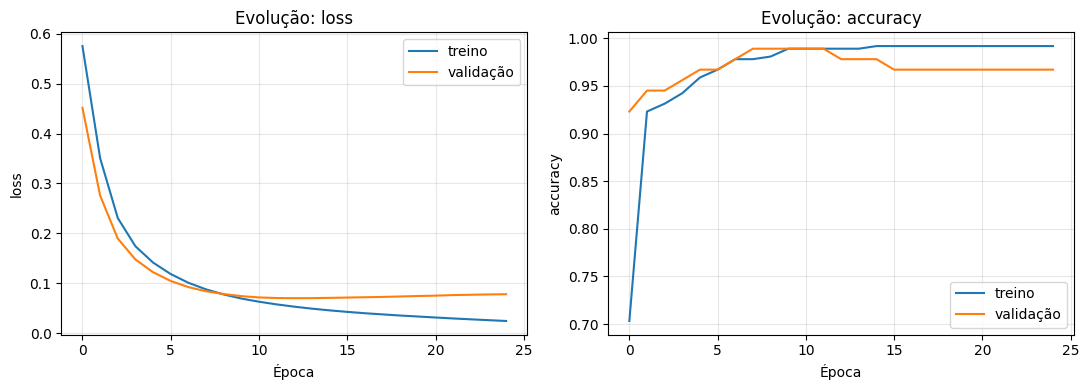

Teste: {'accuracy': 0.9561403393745422, 'auc': 0.9938823580741882, 'loss': 0.10488898307085037, 'precision': 0.9718309640884399, 'recall': 0.9583333134651184}


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, chave in zip(axes, ["loss", "accuracy"]):
    ax.plot(hist_cls.history[chave], label="treino")
    ax.plot(hist_cls.history["val_"+chave], label="validação")
    ax.set(xlabel="Época", ylabel=chave, title=f"Evolução: {chave}")
    ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()
print("Teste:", classificador.evaluate(X_test, y_test, return_dict=True, verbose=0))

              precision    recall  f1-score   support

   malignant       0.93      0.95      0.94        42
      benign       0.97      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



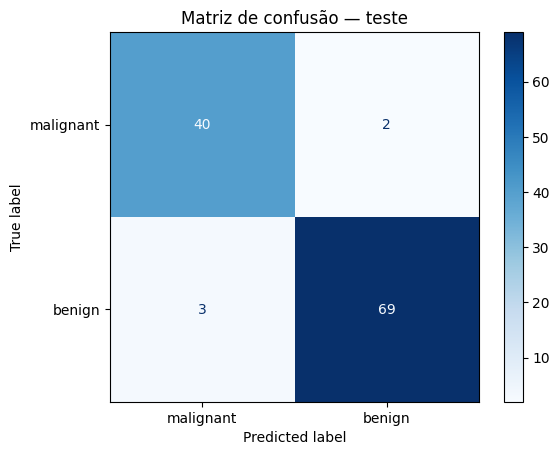

Probabilidades das primeiras amostras: [0.    1.    0.02  0.382 0.    0.99  1.    0.   ]


In [22]:
prob = classificador.predict(X_test, verbose=0).ravel()
y_pred = (prob >= 0.5).astype(int)
print(classification_report(y_test.astype(int), y_pred,
                            target_names=list(base.target_names), zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test.astype(int), y_pred),
                       display_labels=base.target_names).plot(cmap="Blues")
plt.title("Matriz de confusão — teste"); plt.show()
print("Probabilidades das primeiras amostras:", np.round(prob[:8], 3))

**Interpretação:** compare perda e acurácia entre treino e validação; observe se há indícios de sobreajuste. Em aplicações reais, o custo de falsos negativos e falsos positivos pode exigir um limiar diferente de 0,5.

# Exemplo de Regressão (dataset Diabetes)

In [23]:
from sklearn.datasets import load_diabetes
base_reg = load_diabetes()
Xr = base_reg.data.astype("float32")
yr = base_reg.target.astype("float32")
Xr_trainval, Xr_test, yr_trainval, yr_test = train_test_split(
    Xr, yr, test_size=0.20, random_state=42)
Xr_train, Xr_val, yr_train, yr_val = train_test_split(
    Xr_trainval, yr_trainval, test_size=0.20, random_state=42)
scaler_reg = StandardScaler()
Xr_train = scaler_reg.fit_transform(Xr_train).astype("float32")
Xr_val = scaler_reg.transform(Xr_val).astype("float32")
Xr_test = scaler_reg.transform(Xr_test).astype("float32")
print("Dimensões:", Xr.shape, "Treino/validação/teste:",
      len(Xr_train), len(Xr_val), len(Xr_test))

Dimensões: (442, 10) Treino/validação/teste: 282 71 89


In [24]:
keras.utils.set_random_seed(42)
regressor = keras.Sequential([
    layers.Input(shape=(Xr_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="linear")
])
regressor.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.MeanSquaredError(),
    metrics=[keras.metrics.MeanAbsoluteError(name="mae"),
             keras.metrics.RootMeanSquaredError(name="rmse")]
)
hist_reg = regressor.fit(
    Xr_train, yr_train, validation_data=(Xr_val, yr_val),
    epochs=250, batch_size=16, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                             restore_best_weights=True)]
)
print("Épocas executadas:", len(hist_reg.history["loss"]))
print("Teste:", regressor.evaluate(Xr_test, yr_test, return_dict=True, verbose=0))

Épocas executadas: 223
Teste: {'loss': 2820.837890625, 'mae': 42.26510238647461, 'rmse': 53.1115608215332}


MAE: 42.265098571777344
RMSE: 53.11155850174588
R²: 0.4675808548927307


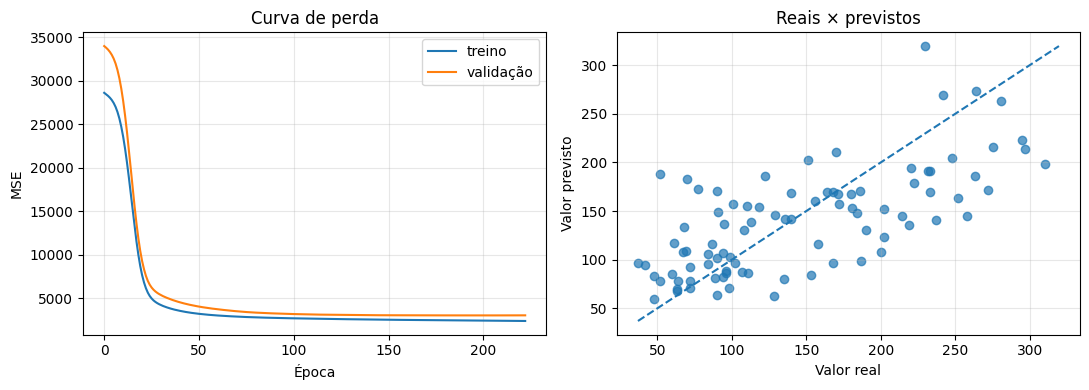

In [25]:
pred_reg = regressor.predict(Xr_test, verbose=0).ravel()
print("MAE:", mean_absolute_error(yr_test, pred_reg))
print("RMSE:", np.sqrt(mean_squared_error(yr_test, pred_reg)))
print("R²:", r2_score(yr_test, pred_reg))
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(hist_reg.history["loss"], label="treino")
axes[0].plot(hist_reg.history["val_loss"], label="validação")
axes[0].set(xlabel="Época", ylabel="MSE", title="Curva de perda")
axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].scatter(yr_test, pred_reg, alpha=.7)
limites = [min(yr_test.min(), pred_reg.min()), max(yr_test.max(), pred_reg.max())]
axes[1].plot(limites, limites, linestyle="--")
axes[1].set(xlabel="Valor real", ylabel="Valor previsto", title="Reais × previstos")
axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

**Interpretação:** MAE e RMSE são expressos nas unidades do alvo. O RMSE penaliza mais os erros grandes. Um R² baixo ou negativo indica que o modelo não está explicando bem a variabilidade no conjunto de teste. Compare sempre com um preditor de referência, como a média do treino.

In [26]:
baseline = np.full_like(yr_test, fill_value=yr_train.mean())
print("Baseline MAE:", mean_absolute_error(yr_test, baseline))
print("Rede MAE:", mean_absolute_error(yr_test, pred_reg))

Baseline MAE: 63.5286865234375
Rede MAE: 42.265098571777344


# Referências
- Keras 3: https://keras.io/
- Modelos Sequential: https://keras.io/guides/sequential_model/
- Functional API: https://keras.io/guides/functional_api/
- Subclassing: https://keras.io/guides/making_new_layers_and_models_via_subclassing/
- Ativações: https://keras.io/api/layers/activations/
- Otimizadores: https://keras.io/api/optimizers/
- Perdas: https://keras.io/api/losses/
- Métricas: https://keras.io/api/metrics/
- Callbacks: https://keras.io/api/callbacks/